# Choosing an identification method: SSI-Cov, SSI-Data or harmonic inversion

pyharminv offers three ways to get frequencies and damping from a
measured signal:

| method | input | model |
|---|---|---|
| `harminv` | free decay, ring-down, impulse response | deterministic sum of damped exponentials |
| `ssi_cov` | response to unknown broadband excitation | stochastic state space, from output correlations |
| `ssi_data` | response to unknown broadband excitation | stochastic state space, from projections of the raw data |

This notebook compares them on the same system, the three-mass chain of
notebook 05, and works out when each is the better choice. The short
answer is at the end.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

from pyharminv import (harminv, output_correlation, random_vibration, ssi,
                       ssi_cov, ssi_data, ssi_stabilization)

plt.rcParams["figure.figsize"] = (9, 4)
np.set_printoptions(precision=4, suppress=True)

M = np.eye(3)
k = np.array([1.0, 1.5, 2.0])
K = np.diag(k + np.append(k[1:], 0)) - np.diag(k[1:], 1) - np.diag(k[1:], -1)
C = 0.02 * M + 0.02 * K
dt = 0.3
_, omega_true = random_vibration(M, C, K, dt, 10)
zeta_true = -omega_true.imag / np.abs(omega_true)
period = 2 * np.pi / omega_true.real.min()
print("true omega:", omega_true, "  slowest period:", round(period, 1))


def errors(result, omega=omega_true):
    """Relative errors of frequency and damping ratio, closest pole per mode."""
    idx = [np.argmin(np.abs(result.omega - w)) for w in omega]
    w = result.omega[idx]
    zeta = -w.imag / np.abs(w)
    z_true = -omega.imag / np.abs(omega)
    return (w.real - omega.real) / omega.real, (zeta - z_true) / z_true


def typical(a, axis=0):
    """Median absolute error: robust against the occasional outlier."""
    return np.nanmedian(np.abs(a), axis=axis)

true omega: [0.4866-0.0124j 1.5262-0.0333j 2.3299-0.0643j]   slowest period: 12.9


## 1. If you can measure a free decay, use harmonic inversion

The most important question is not which SSI variant to use but whether
a free decay can be measured: an impulse (hammer test), a released
deflection, the ring-down after switching off a drive. A free decay is
*deterministic*: the only uncertainty is measurement noise. A response
to random excitation carries its own randomness, the excitation, which
no method can remove; it is averaged out only slowly.

We compare 30 realisations of

* a free decay after an impulse on all masses, 1000 samples (about 23
  periods of the slowest mode), 1 % measurement noise, analysed with
  `harminv` per channel (each mode taken from the channel where it is
  strongest), with
* SSI-Cov of the random response with the same 1 % measurement noise,
  for 1000 and for 30 000 samples.

Velocities are measured here (in displacements the third mode is too weak
to be seen in a free decay with 1 % noise).

In [2]:
def free_decay(n, noise, rng):
    f = np.zeros((n + 1, 3))
    f[0] = 1 / dt                        # a short unit impulse on every mass
    y, _ = random_vibration(M, C, K, dt, n + 1, force=f, output="velocity")
    y = y[1:]
    return y + noise * y.std(axis=0) * rng.standard_normal(y.shape)


def harminv_channels(y):
    """harminv on each channel; per mode the strongest pole within 10 %."""
    res = [harminv(y[:, j], dt, tol=1e-3) for j in range(y.shape[1])]
    best = []
    for w in omega_true:
        cand = [(r.magnitude[i], r.omega[i]) for r in res
                for i in np.flatnonzero(np.abs(r.omega - w) < 0.1 * abs(w))]
        best.append(max(cand, key=lambda c: c[0])[1] if cand else np.nan)
    return np.array(best)


reps = 30
rows = {"harminv, free decay, N=1000": [], "SSI-Cov, random, N=1000": [],
        "SSI-Cov, random, N=30000": []}
for s in range(reps):
    rng = np.random.default_rng(s)
    w = harminv_channels(free_decay(1000, 0.01, rng))
    rows["harminv, free decay, N=1000"].append(
        [(w.real - omega_true.real) / omega_true.real,
         (-w.imag / np.abs(w) - zeta_true) / zeta_true])
    for n in (1000, 30000):
        y, _ = random_vibration(M, C, K, dt, n, noise=0.01, output="velocity",
                                rng=s)
        rows[f"SSI-Cov, random, N={n}"].append(
            errors(ssi_cov(y, dt, order=12, block_rows=30)))

print(f"{'':32s} {'median |freq. error| / %':>26s}   {'median |damping error| / %':>26s}")
for name, e in rows.items():
    e = np.array(e)                       # reps x 2 x modes
    print(f"{name:32s} {np.array2string(100 * typical(e[:, 0]), precision=3):>26s}   "
          f"{np.array2string(100 * typical(e[:, 1]), precision=1):>26s}")

                                   median |freq. error| / %   median |damping error| / %
harminv, free decay, N=1000             [0.002 0.004 0.051]                [0.1 0.2 2.8]
SSI-Cov, random, N=1000                 [0.985 0.883 0.484]             [45.1 34.1 35.5]
SSI-Cov, random, N=30000                [0.232 0.127 0.199]                [6.8 6.  5.7]


The free decay of 1000 samples beats even 30 times as long a random
record by an order of magnitude or more, in frequency and in damping.
With equal length the random response is hopeless for damping.

So: **whenever a free decay or impulse response is available, use
`harminv` on it.** SSI is for the cases where it is not: the system
cannot be stopped or excited artificially, or the operating condition
itself (temperature, rotation, flow, amplitude) matters.

Harmonic inversion of the *raw* random response does not work at all (see
notebook 05, section 2). What does work is harmonic inversion of the
output **correlation function**, which for white-noise excitation decays
like a free response (NExT). With one channel this is close to SSI-Cov.
It is included in the comparisons below as "NExT + harminv".

## 2. Accuracy versus record length

For the random response, how do SSI-Cov, SSI-Data and NExT + harminv
compare? 30 realisations per record length, 10 % measurement noise. The
plots show the median absolute error, which is not dominated by the rare
realisation where a spurious pole lands next to a mode.

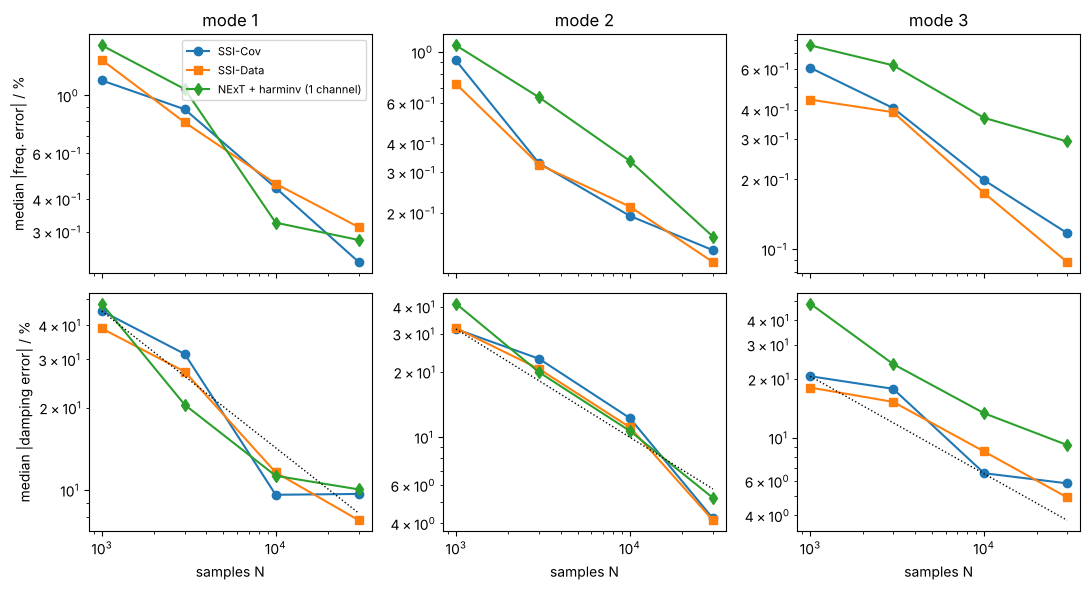

In [3]:
lengths = [1000, 3000, 10000, 30000]
methods = ["SSI-Cov", "SSI-Data", "NExT + harminv (1 channel)"]
err = {m: [] for m in methods}
for n in lengths:
    per = {m: [] for m in methods}
    for s in range(reps):
        y, _ = random_vibration(M, C, K, dt, n, noise=0.1, rng=s)
        per["SSI-Cov"].append(errors(ssi_cov(y, dt, order=12, block_rows=30)))
        per["SSI-Data"].append(errors(ssi_data(y, dt, order=12, block_rows=30)))
        R = output_correlation(y, 120)[1:, 0, 0]     # mass 1 sees all modes
        per["NExT + harminv (1 channel)"].append(errors(harminv(R, dt, tol=1e-3, t0=dt)))
    for m in methods:
        err[m].append(typical(np.array(per[m])))         # 2 x modes
err = {m: np.array(v) for m, v in err.items()}       # lengths x 2 x modes

fig, axs = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for j in range(3):
    for m, mk in zip(methods, "osd"):
        axs[0, j].loglog(lengths, 100 * np.abs(err[m][:, 0, j]), mk + "-", label=m)
        axs[1, j].loglog(lengths, 100 * np.abs(err[m][:, 1, j]), mk + "-", label=m)
    axs[0, j].set_title(f"mode {j + 1}")
    axs[1, j].set_xlabel("samples N")
    n_ = np.array(lengths, float)
    axs[1, j].loglog(n_, 100 * err["SSI-Cov"][0, 1, j] * np.sqrt(n_[0] / n_), "k:", lw=1)
axs[0, 0].set_ylabel("median |freq. error| / %")
axs[1, 0].set_ylabel("median |damping error| / %")
axs[0, 0].legend(fontsize=8)
fig.tight_layout()

* All three converge roughly like $1/\sqrt{N}$ (dotted, for the damping). The error is dominated by
  the randomness of the excitation, which all methods face alike.
* **SSI-Cov and SSI-Data are statistically about equally accurate.**
  This agrees with the literature (Peeters & De Roeck 2001): both
  estimate the same model, with different weightings of the same data.
  SSI-Data tends to be a little better for the shortest records, where
  the correlation estimates at large lags are poor; the difference is
  small compared to the overall uncertainty.
* NExT + harminv on a single channel is close for the modes that are
  strong in that channel, clearly worse for the weak third mode, and it
  has no mode shapes.

## 3. Cost

SSI-Cov works on the correlation estimates, which an FFT computes in
$O(N \log N)$; after that the cost does not depend on $N$. SSI-Data runs a
QR factorisation over the block Hankel matrix with $2 i l$ rows and about
$N$ columns, $O(N (2il)^2)$.

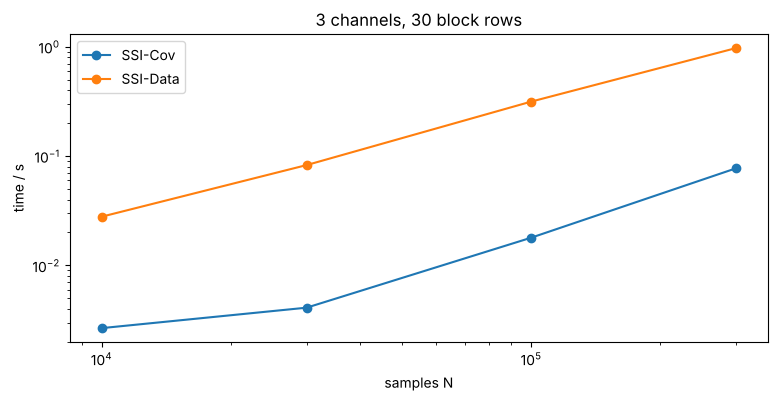

In [4]:
times = {"SSI-Cov": [], "SSI-Data": []}
ns = [10_000, 30_000, 100_000, 300_000]
y_long, _ = random_vibration(M, C, K, dt, ns[-1], noise=0.1, rng=0)
ssi_cov(y_long[:1000], dt, order=12, block_rows=30)       # warm-up
for n in ns:
    for name, fn in (("SSI-Cov", ssi_cov), ("SSI-Data", ssi_data)):
        best = np.inf
        for _ in range(3):
            t0 = time.perf_counter()
            fn(y_long[:n], dt, order=12, block_rows=30)
            best = min(best, time.perf_counter() - t0)
        times[name].append(best)
for name, v in times.items():
    plt.loglog(ns, v, "o-", label=name)
plt.xlabel("samples N")
plt.ylabel("time / s")
plt.title("3 channels, 30 block rows")
plt.legend();

SSI-Data is about ten times slower and grows linearly with the record
length and quadratically with `block_rows * n_channels`. For a handful of
channels both are fast enough; with tens of channels and long records,
SSI-Cov (or SSI-Data with reference channels, not implemented here) is
the practical choice. The stabilization diagram costs little more than one
identification for either variant, since all orders share one SVD.

## 4. Closely spaced modes: more channels beat more data

Two nearly identical oscillators with a weak coupling have two modes one
line width apart, with shapes $(1, 1)$ and $(1, -1)$ approximately. We
count in how many of 10 realisations each method finds both modes (each
within a quarter of their spacing).

In [5]:
M2 = np.eye(2)
K2 = np.array([[1.01, -0.01], [-0.01, 1.014]])
C2 = 0.005 * K2 + 0.005 * M2
dt2 = 0.5
_, om2 = random_vibration(M2, C2, K2, dt2, 10)
spacing = om2[1].real - om2[0].real
print("modes:", om2, "  spacing / line width:", spacing / (-2 * om2[0].imag))


def found_both(r):
    r = r.select(max_damping=0.1)
    r = r.select(min_magnitude=1e-2 * r.magnitude.max())
    return max(np.min(np.abs(r.omega - w)) for w in om2) < 0.25 * spacing


print(f"{'N':>7s} {'Cov, 1 ch':>10s} {'Cov, 2 ch':>10s} {'Data, 1 ch':>11s} {'Data, 2 ch':>11s}")
for n in (5000, 20000, 80000):
    hits = np.zeros(4, int)
    for s in range(10):
        y, _ = random_vibration(M2, C2, K2, dt2, n, noise=0.1, rng=s)
        for c, (fn, ch) in enumerate([(ssi_cov, [0]), (ssi_cov, [0, 1]),
                                      (ssi_data, [0]), (ssi_data, [0, 1])]):
            hits[c] += found_both(fn(y[:, ch], dt2, order=8, block_rows=60))
    print(f"{n:7d} {hits[0]:>10d} {hits[1]:>10d} {hits[2]:>11d} {hits[3]:>11d}")

modes: [1.0009-0.005j  1.011 -0.0051j]   spacing / line width: 1.0128271115017276
      N  Cov, 1 ch  Cov, 2 ch  Data, 1 ch  Data, 2 ch


   5000          0          4           0           3


  20000          0          8           0          10


  80000          0         10           0          10


With a single channel, neither variant separates the two modes, even from
80 000 samples: the random spectrum of one channel cannot tell two
overlapping lines from one. With both channels, the different mode shapes
separate them easily. This is the main strength of SSI over
single-channel methods: **measure at several points.** Neither variant is
clearly better here.

## 5. When the excitation is not white

SSI assumes white-noise excitation. Real excitation is coloured, and it
often contains harmonic components, for example from rotating machinery.

### Harmonic components

A sine force at $\omega = 1$ on mass 1, on top of the white noise:

In [6]:
N = 30_000
t = dt * np.arange(N)
rng = np.random.default_rng(5)
force = rng.standard_normal((N, 3))
force[:, 0] += 3 * np.sin(1.0 * t)
y, _ = random_vibration(M, C, K, dt, N, force=force)
r = ssi_cov(y, dt, order=16, block_rows=40).select(max_rel_error=0.01)
print(r)

SSIResult with 4 modes, order 16, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.4887169     -0.0138182    0.02826       3.895   0.00011
      1.000031  -6.969876e-05   6.97e-05      0.4993   1.8e-05
      1.525917    -0.03092382    0.02026      0.6269    0.0029
      2.336204    -0.06698917    0.02866     0.03197    0.0039


The harmonic appears as a fourth "mode" with a damping ratio of almost
zero: in the stochastic model it is a pole on the unit circle. It is easy
to recognise (damping orders of magnitude below the structural modes,
identical in all orders, often a known machine speed) and to remove with
`select(min_damping=...)`. A harmonic *close to* a mode is harder; it
biases that mode's damping.

In [7]:
print(r.select(min_damping=1e-3))

SSIResult with 3 modes, order 16, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.4887169     -0.0138182    0.02826       3.895   0.00011
      1.525917    -0.03092382    0.02026      0.6269    0.0029
      2.336204    -0.06698917    0.02866     0.03197    0.0039


### Coloured excitation

Now the force is white noise passed through a low-pass filter with a
corner frequency of $\omega = 0.8$, so modes 2 and 3 are excited far
less than mode 1:

In [8]:
b, a = butter(2, 0.8 * dt / np.pi)
force = lfilter(b, a, rng.standard_normal((N, 3)), axis=0)
y, _ = random_vibration(M, C, K, dt, N, force=force)
r = ssi_cov(y, dt, order=16, block_rows=40).select(max_rel_error=0.01)
print(r)
print("poles of the excitation filter:", 1j * np.log(np.roots(a).astype(complex)) / dt)

SSIResult with 3 modes, order 16, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.4869822    -0.01265313    0.02597       3.596    0.0011
      1.524355    -0.03363516    0.02206      0.0428   0.00065
      2.323843    -0.06043329      0.026   0.0003693   0.00067
poles of the excitation filter: [-0.5711-0.5656j  0.5711-0.5656j]


The structural modes are still found, with the expected statistical
errors, although mode 3 receives only about 1/70 of the excitation
power that a white force would give it. The
excitation filter has poles of its own; SSI identifies the system *plus*
the filter that colours the excitation. Here those poles are heavily
damped (ζ ≈ 0.7) and do not stabilise, so `select` drops them. Narrow-band
excitation would create sharp, stable "modes" of the excitation that look
like structural ones; they can only be told apart by physics, or by
repeating the measurement under different operating conditions.

## 6. Summary: which method when?

| situation | recommended |
|---|---|
| free decay, ring-down or impulse response available | `harminv` (deterministic, by far the most accurate) |
| only operational response to broadband excitation, several channels | `ssi_cov` for exploring (stabilization diagram), then `ssi_cov` or `ssi_data` |
| short records, weakly excited or closely spaced modes | `ssi_data` (slightly more accurate, numerically more robust) |
| long records, many channels, limited time | `ssi_cov` (cost independent of N after one FFT) |
| single channel, quick look | `ssi_cov` on that channel, or `harminv` of its correlation function |
| closely spaced modes | more channels, then either SSI variant |
| strong harmonic components in the excitation | either SSI variant, remove poles with ζ ≈ 0 via `select(min_damping=...)` |

In all cases: remove the mean, sample not much faster than needed,
choose the order generously and check it with `ssi_stabilization`, and
remember that the damping of a randomly excited system is only known to
within a statistical error that shrinks like $1/\sqrt{T}$.